<a href="https://colab.research.google.com/github/Matthew-Calvario/Airport-Delay-Prediction/blob/main/DS_3001_1_month_Preliminary_Analysis_(January).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


```markdown
# Importing data and initial EDA
```

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

```markdown
# Data loading
```

In [ ]:
# Load the dataset from Google Drive
# Note: Adjust the path if the file is inside a specific folder
df = pd.read_csv('/content/drive/MyDrive/T_ONTIME_REPORTING_JANUARY.csv')
display(df.head())

,YEAR,MONTH,DAY_OF_WEEK,FL_DATE,OP_UNIQUE_CARRIER,ORIGIN_AIRPORT_ID,ORIGIN,DEST_AIRPORT_ID,CRS_DEP_TIME,DEP_TIME,DEP_DELAY,DEP_DEL15,CANCELLED,DIVERTED
0,2025,1,1,1/6/2025 12:00:00 AM,AA,10140,ABQ,11298,500,454.0,-6.0,0.0,0.0,0.0
1,2025,1,1,1/6/2025 12:00:00 AM,AA,10140,ABQ,11298,555,623.0,28.0,1.0,0.0,0.0
2,2025,1,1,1/6/2025 12:00:00 AM,AA,10140,ABQ,11298,820,NaN,NaN,NaN,1.0,0.0
3,2025,1,1,1/6/2025 12:00:00 AM,AA,10140,ABQ,11298,1032,1027.0,-5.0,0.0,0.0,0.0
4,2025,1,1,1/6/2025 12:00:00 AM,AA,10140,ABQ,11298,1650,1732.0,42.0,1.0,0.0,0.0


```markdown
# Basic EDA
```

In [ ]:
# Print shapes, null values, and structural info
print("Shape:", df.shape)
print("\nNulls:")
print(df.isnull().sum())
print("\nInfo:")
df.info()

Shape: (539747, 14)

Nulls:
YEAR                     0
MONTH                    0
DAY_OF_WEEK              0
FL_DATE                  0
OP_UNIQUE_CARRIER        0
ORIGIN_AIRPORT_ID        0
ORIGIN                   0
DEST_AIRPORT_ID          0
CRS_DEP_TIME             0
DEP_TIME             15886
DEP_DELAY            15923
DEP_DEL15            15923
CANCELLED                0
DIVERTED                 0
dtype: int64

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 539747 entries, 0 to 539746
Data columns (total 14 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   YEAR               539747 non-null  int64  
 1   MONTH              539747 non-null  int64  
 2   DAY_OF_WEEK        539747 non-null  int64  
 3   FL_DATE            539747 non-null  object 
 4   OP_UNIQUE_CARRIER  539747 non-null  object 
 5   ORIGIN_AIRPORT_ID  539747 non-null  int64  
 6   ORIGIN             539747 non-null  object 
 7   DEST_AIRPORT_ID  

In [ ]:
# 1. Data Validation and Cleaning
# Define the four target Virginia airports
va_airports = ['IAD', 'DCA', 'RIC', 'CHO']

# Filter for flights originating from target Virginia airports
df_cleaned = df[df['ORIGIN'].isin(va_airports)].copy()
origin_filtered_count = len(df_cleaned)
print(f"Flights originating from target VA airports ({va_airports}): {origin_filtered_count}")

# Ensure that cancelled and diverted flights are excluded
df_cleaned = df_cleaned[(df_cleaned['CANCELLED'] == 0) & (df_cleaned['DIVERTED'] == 0)].copy()
non_cancelled_diverted_count = len(df_cleaned)
print(f"Active flights (excluding cancelled/diverted): {non_cancelled_diverted_count}")
print(f"Excluded: {origin_filtered_count - non_cancelled_diverted_count} flights (Cancelled/Diverted)")

# Ensure target variable is valid (DEP_DEL15 indicates departure delay >= 15 min)
# Check for missing values in DEP_DEL15 and drop if any exist
null_delays = df_cleaned['DEP_DEL15'].isnull().sum()
print(f"Missing target indicator (DEP_DEL15) in active dataset: {null_delays}")
if null_delays > 0:
    df_cleaned = df_cleaned.dropna(subset=['DEP_DEL15']).copy()

# Re-verify and map clean binary target variable
df_cleaned['TARGET'] = df_cleaned['DEP_DEL15'].astype(int)

# Use CRS_DEP_TIME (scheduled departure time) instead of DEP_TIME to avoid data leakage
# CRS_DEP_TIME format is HHMM (e.g. 1730 -> 17). Safe conversion to hour:
df_cleaned['SCHED_DEP_HOUR'] = (df_cleaned['CRS_DEP_TIME'] // 100).astype(int)

print(f"Final validated analytical dataset size: {len(df_cleaned)}")

Flights originating from target VA airports (['IAD', 'DCA', 'RIC', 'CHO']): 17028
Active flights (excluding cancelled/diverted): 15730
Excluded: 1298 flights (Cancelled/Diverted)
Missing target indicator (DEP_DEL15) in active dataset: 0
Final validated analytical dataset size: 15730


In [ ]:
# 2. Preliminary Descriptive Statistics
print("Overall Delay Rate")
overall_delay_rate = df_cleaned['TARGET'].mean()
print(f"Total Cleaned Flights: {len(df_cleaned)}")
print(f"Overall Delay Rate: {overall_delay_rate:.2%}\n")

print("Delay Rate by Origin Airport")
airport_stats = df_cleaned.groupby('ORIGIN').agg(
    Total_Flights=('TARGET', 'count'),
    Delayed_Flights=('TARGET', 'sum'),
    Delay_Rate=('TARGET', 'mean')
).reset_index()
display(airport_stats)

print("\n Delay Rate by Airline")
airline_stats = df_cleaned.groupby('OP_UNIQUE_CARRIER').agg(
    Total_Flights=('TARGET', 'count'),
    Delayed_Flights=('TARGET', 'sum'),
    Delay_Rate=('TARGET', 'mean')
).reset_index().sort_values(by='Delay_Rate', ascending=False)
display(airline_stats)

print("\n Delay Rate by Scheduled Departure Hour")
hour_stats = df_cleaned.groupby('SCHED_DEP_HOUR').agg(
    Total_Flights=('TARGET', 'count'),
    Delayed_Flights=('TARGET', 'sum'),
    Delay_Rate=('TARGET', 'mean')
).reset_index()
display(hour_stats.head(24))

Overall Delay Rate
Total Cleaned Flights: 15730
Overall Delay Rate: 19.75%

Delay Rate by Origin Airport


,ORIGIN,Total_Flights,Delayed_Flights,Delay_Rate
0,CHO,84,15,0.178571
1,DCA,10619,2192,0.206422
2,IAD,3872,717,0.185176
3,RIC,1155,182,0.157576



 Delay Rate by Airline


,OP_UNIQUE_CARRIER,Total_Flights,Delayed_Flights,Delay_Rate
8,OH,3420,1051,0.307310
1,AS,224,65,0.290179
3,DL,1084,243,0.224170
5,G4,47,10,0.212766
9,OO,361,72,0.199446
11,WN,1470,286,0.194558
4,F9,155,30,0.193548
6,MQ,386,73,0.189119
7,NK,67,12,0.179104
2,B6,624,108,0.173077



 Delay Rate by Scheduled Departure Hour


,SCHED_DEP_HOUR,Total_Flights,Delayed_Flights,Delay_Rate
0,5,144,8,0.055556
1,6,1231,120,0.097482
2,7,758,94,0.124011
3,8,1862,271,0.145542
4,9,621,109,0.175523
5,10,1064,175,0.164474
6,11,708,110,0.155367
7,12,1181,254,0.215072
8,13,893,202,0.226204
9,14,821,203,0.247259


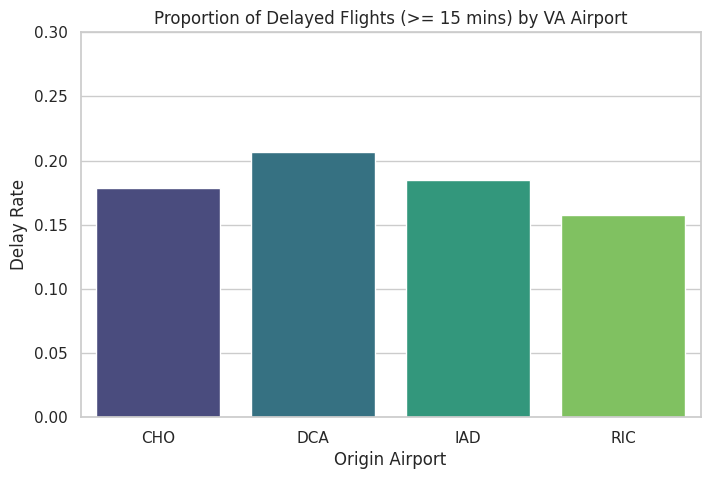

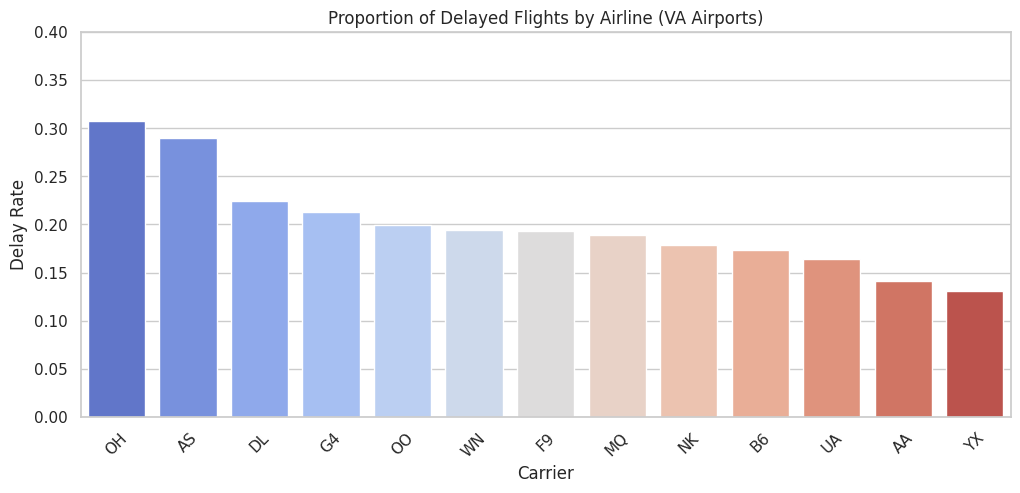

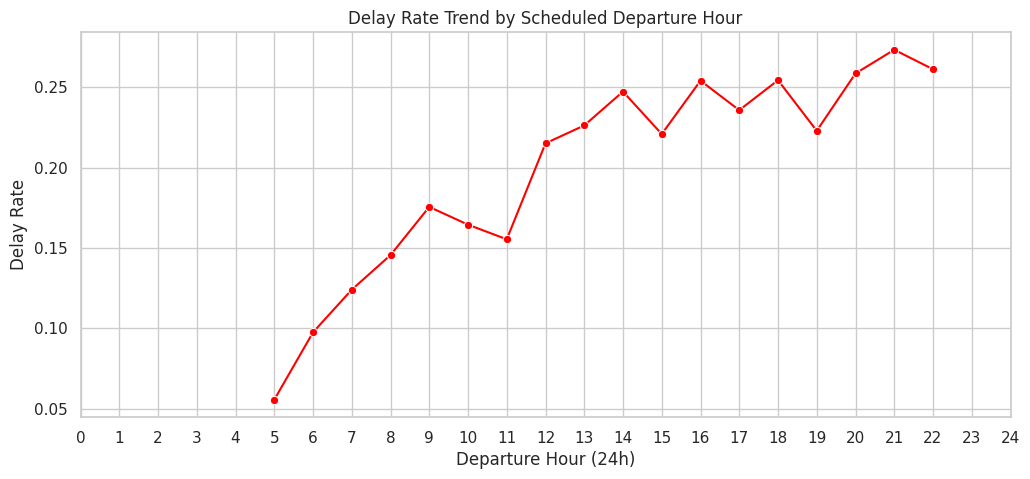

In [ ]:
# 3. Exploratory Data Visualizations for VA Airport Scope

# Plot 1: Delay Rate by Origin Airport
plt.figure(figsize=(8, 5))
sns.barplot(data=airport_stats, x='ORIGIN', y='Delay_Rate', hue='ORIGIN', legend=False, palette='viridis')
plt.title('Proportion of Delayed Flights (>= 15 mins) by VA Airport')
plt.ylabel('Delay Rate')
plt.xlabel('Origin Airport')
plt.ylim(0, 0.30)
plt.show()

# Plot 2: Delay Rate by Airline (with volume annotation)
plt.figure(figsize=(12, 5))
sns.barplot(data=airline_stats, x='OP_UNIQUE_CARRIER', y='Delay_Rate', hue='OP_UNIQUE_CARRIER', legend=False, palette='coolwarm')
plt.title('Proportion of Delayed Flights by Airline (VA Airports)')
plt.ylabel('Delay Rate')
plt.xlabel('Carrier')
plt.ylim(0, 0.40)
plt.xticks(rotation=45)
plt.show()

# Plot 3: Delay Rate by Hour of Day
plt.figure(figsize=(12, 5))
sns.lineplot(data=hour_stats[hour_stats['SCHED_DEP_HOUR'].between(1, 24)], x='SCHED_DEP_HOUR', y='Delay_Rate', marker='o', color='red')
plt.title('Delay Rate Trend by Scheduled Departure Hour')
plt.ylabel('Delay Rate')
plt.xlabel('Departure Hour (24h)')
plt.xticks(range(0, 25))
plt.grid(True)
plt.show()

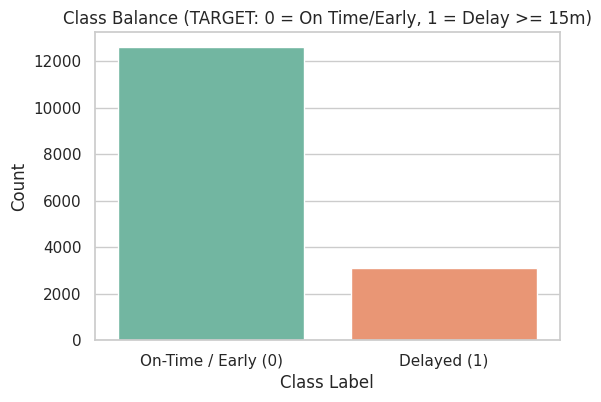

In [ ]:
# Plot 4: Target Variable Class Distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df_cleaned, x='TARGET', hue='TARGET', legend=False, palette='Set2')
plt.title('Class Balance (TARGET: 0 = On Time/Early, 1 = Delay >= 15m)')
plt.xlabel('Class Label')
plt.ylabel('Count')
plt.xticks([0, 1], ['On-Time / Early (0)', 'Delayed (1)'])
plt.show()

In [ ]:
# 4. Supplementary Analysis: Delay Rate by Day of Week (VA Scope)
print("=== Delay Rate by Day of Week ===")
day_stats = df_cleaned.groupby('DAY_OF_WEEK').agg(
    Total_Flights=('TARGET', 'count'),
    Delayed_Flights=('TARGET', 'sum'),
    Delay_Rate=('TARGET', 'mean')
).reset_index()

# Map days to names
day_mapping = {1: 'Monday', 2: 'Tuesday', 3: 'Wednesday', 4: 'Thursday', 5: 'Friday', 6: 'Saturday', 7: 'Sunday'}
day_stats['Day_Name'] = day_stats['DAY_OF_WEEK'].map(day_mapping)
display(day_stats[['Day_Name', 'Total_Flights', 'Delayed_Flights', 'Delay_Rate']])

=== Delay Rate by Day of Week ===


,Day_Name,Total_Flights,Delayed_Flights,Delay_Rate
0,Monday,1890,489,0.258730
1,Tuesday,2112,427,0.202178
2,Wednesday,2626,366,0.139375
3,Thursday,2545,404,0.158743
4,Friday,2705,603,0.222921
5,Saturday,1768,375,0.212104
6,Sunday,2084,442,0.212092


In [ ]:
# 5. Machine Learning Readiness Assessment & Checklist

# Verify target representation counts for class imbalance
class_counts = df_cleaned['TARGET'].value_counts()
class_pcts = df_cleaned['TARGET'].value_counts(normalize=True)
print("TARGET Class Balance")
for cls, count in class_counts.items():
    print(f"Class {cls}: {count} flights ({class_pcts[cls]:.2%})")

# Identify categorical variables needing encoding
categorical_cols = ['OP_UNIQUE_CARRIER', 'ORIGIN', 'DAY_OF_WEEK']
print("\n Categorical Encoding Requirements")
for col in categorical_cols:
    unique_vals = df_cleaned[col].nunique()
    print(f"'{col}' is categorical with {unique_vals} unique classes.")

TARGET Class Balance
Class 0: 12624 flights (80.25%)
Class 1: 3106 flights (19.75%)

 Categorical Encoding Requirements
'OP_UNIQUE_CARRIER' is categorical with 13 unique classes.
'ORIGIN' is categorical with 4 unique classes.
'DAY_OF_WEEK' is categorical with 7 unique classes.
